<a href="https://colab.research.google.com/github/LiliiaKuchvara/Python-DTA/blob/main/%D0%98%CC%86%D0%BC%D0%BE%D0%B2%D1%96%D1%80%D0%BD%D1%96%D1%81%D1%82%D1%8C_%D0%B2%D0%B8%D0%B1%D1%96%D1%80%D0%BA%D0%B8_%D0%BA%D0%BE%D1%80%D0%B5%D0%BB%D1%8F%D1%86%D1%96%D1%8F_%D0%BB%D0%B5%D0%BA%D1%86%D1%96%D1%8F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎲 Ймовірність, вибірки та кореляція в Python

**Заняття: ймовірність і вибірки · кореляція та зв'язки між змінними**

Тривалість: **90 хвилин** · Інструменти: `numpy`, `pandas`, `matplotlib`, `scipy`

| # | Тема | Час |
|---|---|---|
| 0 | Вступ | 3 хв |
| 1 | Базові поняття ймовірності | 12 хв |
| 2 | Генеральна сукупність і вибірка | 10 хв |
| 3 | Закон великих чисел | 10 хв |
| 4 | Центральна гранична теорема (інтуїтивно) | 13 хв |
| 5 | Діаграма розсіювання | 7 хв |
| 6 | Коваріація | 8 хв |
| 7 | Коефіцієнт кореляції Пірсона | 12 хв |
| 8 | Кореляція ≠ причинність | 10 хв |
| 9 | Підсумок | 5 хв |
| ✍️ | Перевірте себе (домашнє завдання) | — |

> 💡 Ноутбук можна відкрити в **Google Colab**: *File → Upload notebook*. Усі дані генеруються всередині ноутбука. Щоб пройти все з нуля: *Runtime → Run all*.

---
## 0. Вступ (⏱ 3 хв)

Минулого разу ми **описували** дані, які маємо: середнє, медіана, розкид, форма розподілу.

Сьогодні два нові питання:

1. **Наскільки можна довіряти числам, порахованим на частині даних?** Ми майже ніколи не бачимо *всіх* клієнтів, *всі* покупки, *всіх* виборців. Ми бачимо вибірку. Тут допомагають ймовірність, закон великих чисел і центральна гранична теорема.
2. **Чи пов'язані дві змінні між собою?** Чи ростуть продажі разом із рекламою? Тут допомагають коваріація і кореляція, а також головне застереження: **кореляція — ще не причинність**.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from itertools import product
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (9, 4.5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
pd.set_option('display.float_format', '{:.3f}'.format)

# Фіксований seed: у всіх однакові «випадкові» числа
rng = np.random.default_rng(7)

---
# Частина 1. Ймовірність і вибірки

## 1. Базові поняття ймовірності (⏱ 12 хв)

| Поняття | Що означає | Приклад |
|---|---|---|
| **Експеримент** | дія з випадковим результатом | кинути кубик; відвідувач заходить на сайт |
| **Результат** | один можливий підсумок | випала «4»; відвідувач купив |
| **Подія** | набір результатів, що нас цікавить | «випало парне»; «відвідувач купив хоч щось» |
| **Ймовірність P(A)** | число від 0 до 1, наскільки подія A можлива | P(парне) = 0.5 |

- **P = 0** — подія неможлива, **P = 1** — обов'язково станеться.
- **Конверсія сайту 3%** — це і є ймовірність, що випадковий відвідувач купить: P(купівля) = 0.03.

### Два способи порахувати ймовірність

1. **Класичний** (коли всі результати однаково можливі):
$$P(A) = \frac{\text{кількість сприятливих результатів}}{\text{кількість усіх результатів}}$$
2. **Частотний** (з досвіду або даних): повторюємо експеримент багато разів і рахуємо частку, коли подія сталася.
$$P(A) \approx \frac{\text{скільки разів сталося A}}{\text{скільки було спроб}}$$

### Три базові правила

| Правило | Формула | Приклад |
|---|---|---|
| **Доповнення** («НЕ А») | $P(\text{не }A) = 1 - P(A)$ | P(не купив) = 1 − 0.03 = 0.97 |
| **Додавання** (для подій, які не можуть статися разом) | $P(A \text{ або } B) = P(A) + P(B)$ | P(1 або 2 на кубику) = 1/6 + 1/6 |
| **Множення** (для незалежних подій) | $P(A \text{ і } B) = P(A) \cdot P(B)$ | P(два орли поспіль) = 0.5 · 0.5 = 0.25 |

In [ ]:
# Класичний спосіб: кубик
outcomes = [1, 2, 3, 4, 5, 6]
favorable = [x for x in outcomes if x % 2 == 0]   # парні
print('Сприятливі:', favorable)
print('P(парне) =', len(favorable), '/', len(outcomes), '=', len(favorable) / len(outcomes))

Сприятливі: [2, 4, 6]
P(парне) = 3 / 6 = 0.5


In [ ]:
# Частотний спосіб: «кидаємо» кубик багато разів
for n_rolls in [10, 100, 100_000]:
    rolls = rng.integers(1, 7, size=n_rolls)     # числа від 1 до 6
    freq = (rolls % 2 == 0).mean()
    print(f'{n_rolls:>7} кидків → частка парних = {freq:.3f}')

     10 кидків → частка парних = 0.700
    100 кидків → частка парних = 0.510
 100000 кидків → частка парних = 0.500


👀 На 10 кидках частка може бути будь-якою: 0.3, 0.7… На 100 000 кидках вона майже точно дорівнює 0.5. Це наш перший погляд на **закон великих чисел** (розділ 3).

Усього комбінацій: 36
P(сума = 7) = 6/36 = 0.167


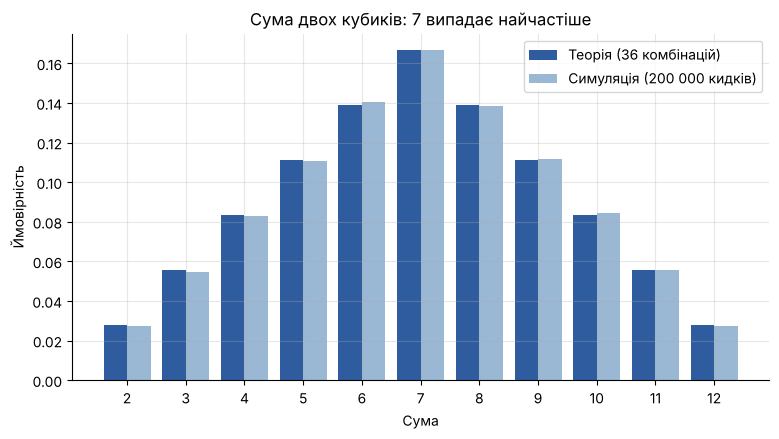

In [ ]:
# Сума двох кубиків: перебираємо всі 36 комбінацій
all_pairs = list(product(range(1, 7), repeat=2))
sums = pd.Series([a + b for a, b in all_pairs])

theory = sums.value_counts(normalize=True).sort_index()
print('Усього комбінацій:', len(all_pairs))
print(f'P(сума = 7) = {(sums == 7).sum()}/36 = {(sums == 7).mean():.3f}')

# Перевіряємо симуляцією
sim = rng.integers(1, 7, size=(200_000, 2)).sum(axis=1)
simulated = pd.Series(sim).value_counts(normalize=True).sort_index()

plt.bar(theory.index - 0.2, theory.values, width=0.4, label='Теорія (36 комбінацій)', color='#2E5C9E')
plt.bar(simulated.index + 0.2, simulated.values, width=0.4, label='Симуляція (200 000 кидків)', color='#9ab7d3')
plt.xticks(range(2, 13))
plt.title('Сума двох кубиків: 7 випадає найчастіше')
plt.xlabel('Сума')
plt.ylabel('Ймовірність')
plt.legend()
plt.show()

### Корисний трюк: «хоча б один»

**Питання:** конверсія сайту — 5%. Яка ймовірність, що з 20 відвідувачів **хоча б один** щось купить?

Рахувати напряму важко: один купив, або двоє, або троє… Легше через **доповнення**:

$$P(\text{хоча б один}) = 1 - P(\text{жоден не купив}) = 1 - 0.95^{20}$$

Тут ми ще й використали **множення**: відвідувачі незалежні, тому P(жоден з 20) = 0.95 · 0.95 · … · 0.95 = 0.95²⁰.

In [ ]:
p, n_visitors = 0.05, 20
p_formula = 1 - (1 - p) ** n_visitors

# Перевіримо симуляцією: 100 000 разів «приводимо» по 20 відвідувачів
bought = rng.random(size=(100_000, n_visitors)) < p   # True = купив
p_sim = bought.any(axis=1).mean()                      # хоча б один True у рядку

print(f'Формула:    {p_formula:.3f}')
print(f'Симуляція:  {p_sim:.3f}')

Формула:    0.642
Симуляція:  0.641


### ⚠️ Помилка гравця

«Монетка 5 разів поспіль упала решкою, отже зараз *точно* має бути орел!» — **ні**. Монетка не пам'ятає попередніх кидків. Кожен кидок **незалежний**, і ймовірність орла завжди 0.5.

Перевіримо на мільйоні кидків: знайдемо всі місця, де було 5 решок поспіль, і подивимось, що випало далі.

In [ ]:
flips = rng.integers(0, 2, size=1_000_000)          # 1 = орел, 0 = решка
windows = np.lib.stride_tricks.sliding_window_view(flips, 6)

after_5_tails = windows[(windows[:, :5] == 0).all(axis=1), 5]   # що випало після 5 решок
print(f'Випадків «5 решок поспіль»: {len(after_5_tails)}')
print(f'Частка орлів одразу після них: {after_5_tails.mean():.3f}')

Випадків «5 решок поспіль»: 30926
Частка орлів одразу після них: 0.503


---
## 2. Генеральна сукупність і вибірка (⏱ 10 хв)

| | Генеральна сукупність | Вибірка |
|---|---|---|
| **Що це** | **усі** об'єкти, які нас цікавлять | **частина**, яку ми реально бачимо |
| **Приклад** | усі клієнти магазину | 500 клієнтів, які заповнили анкету |
| **Числа** | **параметри**: μ (середнє), σ (станд. відхилення), p (частка) | **статистики**: x̄, s, p̂ |
| **Чи знаємо?** | зазвичай **ні** | так — ми їх рахуємо |

**Навіщо вибірки?** Усіх перевірити дорого, довго, а інколи неможливо. Щоб дізнатися, чи досолений суп, не треба з'їдати всю каструлю: достатньо **перемішати** й скуштувати ложку.

**«Перемішати»** тут ключове слово. Вибірка має бути **випадковою**: кожен об'єкт має однаковий шанс у неї потрапити. Інакше виникає **зміщення вибірки** (*sampling bias*).

> 📜 **Історія:** у 1936 році журнал *Literary Digest* опитав 2.4 мільйона американців і передбачив перемогу Лендона над Рузвельтом. Рузвельт переміг із великим відривом. Журнал брав адреси з телефонних довідників і списків власників авто — у часи Великої депресії це були заможніші люди. Джордж Геллап опитав приблизно 50 тисяч, але правильно підібраних людей, і вгадав результат. **Якість вибірки важливіша за її розмір.**

In [ ]:
# «Генеральна сукупність»: 100 000 клієнтів інтернет-магазину
N = 100_000
population = pd.DataFrame({
    'channel': rng.choice(['Застосунок', 'Сайт'], size=N, p=[0.3, 0.7]),
})
# Клієнти застосунку в середньому витрачають більше
base = rng.lognormal(6.3, 0.6, N)
population['check'] = np.round(np.where(population['channel'] == 'Застосунок', base * 1.6, base))

mu = population['check'].mean()
print(f'Параметр генеральної сукупності: μ = {mu:.1f} грн')
print('(у реальному житті ми його НЕ знаємо — тому й беремо вибірки)')

Параметр генеральної сукупності: μ = 771.0 грн
(у реальному житті ми його НЕ знаємо — тому й беремо вибірки)


In [ ]:
# Беремо 5 різних випадкових вибірок по 100 клієнтів
for i in range(5):
    sample = population['check'].sample(100, random_state=i)
    print(f'Вибірка {i + 1}: x̄ = {sample.mean():7.1f} грн   (помилка {sample.mean() - mu:+6.1f})')

Вибірка 1: x̄ =   813.5 грн   (помилка  +42.5)
Вибірка 2: x̄ =   764.9 грн   (помилка   -6.1)
Вибірка 3: x̄ =   711.0 грн   (помилка  -60.0)
Вибірка 4: x̄ =   765.4 грн   (помилка   -5.6)
Вибірка 5: x̄ =   747.3 грн   (помилка  -23.7)


Кожна вибірка дає **трохи інше** середнє. Це нормально, і називається **вибірковою мінливістю**. Що більша вибірка, то менше «стрибає» середнє:

In [ ]:
rows = []
for n in [10, 100, 1_000, 10_000]:
    means = [population['check'].sample(n, random_state=i).mean() for i in range(200)]
    rows.append({'Розмір вибірки': n,
                 'Найменше x̄': min(means),
                 'Найбільше x̄': max(means),
                 'Типова помилка (std)': np.std(means)})
pd.DataFrame(rows).set_index('Розмір вибірки').round(1)

,Найменше x̄,Найбільше x̄,Типова помилка (std)
Розмір вибірки,,,
10,354.800,1453.300,194.400
100,633.800,926.500,56.000
1000,724.900,823.100,16.800
10000,756.600,789.000,5.600


In [ ]:
# ⚠️ Зміщена вибірка: опитування провели лише через push-сповіщення в застосунку
biased = population[population['channel'] == 'Застосунок']['check'].sample(5_000, random_state=1)
fair   = population['check'].sample(500, random_state=1)

print(f'Справжнє середнє (μ):                    {mu:7.1f} грн')
print(f'Випадкова вибірка, n = 500:              {fair.mean():7.1f} грн')
print(f'Зміщена вибірка (лише застосунок), n = 5000: {biased.mean():7.1f} грн')

Справжнє середнє (μ):                      771.0 грн
Випадкова вибірка, n = 500:                726.9 грн
Зміщена вибірка (лише застосунок), n = 5000:  1046.4 грн


> 💡 **Висновок:** вибірка у 10 разів більша, але помилка в рази гірша. **Збільшення вибірки не виправляє зміщення.** Спершу переконайтеся, що вибірка випадкова і представляє всіх, а вже потім думайте про розмір.

---
## 3. Закон великих чисел (⏱ 10 хв)

**Закон великих чисел (ЗВЧ):** якщо повторювати незалежний експеримент багато разів, середнє результатів наближається до справжнього значення (математичного сподівання).

- Частка орлів → 0.5
- Середнє на кубику → 3.5
- Частка покупців серед відвідувачів → справжня конверсія

**Чого ЗВЧ НЕ каже:** що «невдачі мають компенсуватися». Монетка не «вирівнює» рахунок. Просто нові кидки **розбавляють** старі відхилення, і ті перестають бути помітними на тлі тисяч кидків.

**Де це працює в житті:** казино і страхові компанії. В окремій грі казино може програти, але на мільйонах ставок заробіток майже гарантований.

**Зворотний бік — «закон малих чисел»:** люди часто роблять висновки з **малих** вибірок, а там середнє ще дуже «стрибає».

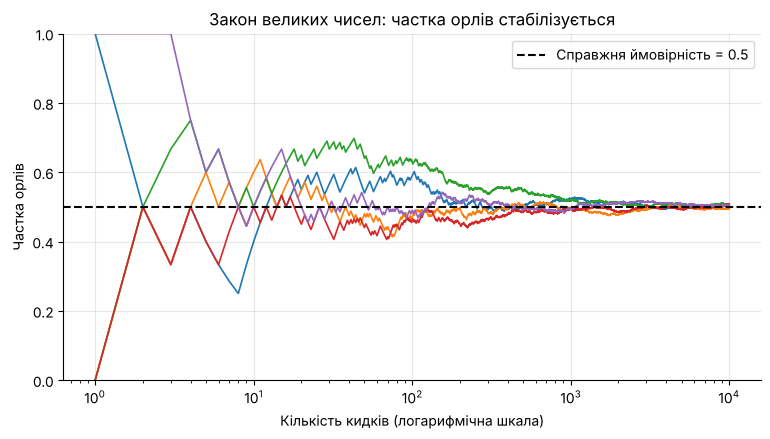

In [ ]:
# 5 «гравців» по 10 000 кидків монетки: як змінюється частка орлів
n_flips = 10_000
steps = np.arange(1, n_flips + 1)

for i in range(5):
    flips = rng.integers(0, 2, size=n_flips)
    running_share = flips.cumsum() / steps          # частка орлів після кожного кидка
    plt.plot(steps, running_share, linewidth=1.2)

plt.axhline(0.5, color='black', linestyle='--', linewidth=1.5, label='Справжня ймовірність = 0.5')
plt.xscale('log')
plt.ylim(0, 1)
plt.title('Закон великих чисел: частка орлів стабілізується')
plt.xlabel('Кількість кидків (логарифмічна шкала)')
plt.ylabel('Частка орлів')
plt.legend()
plt.show()

Зліва (перші 10–50 кидків) лінії розкидані від 0.2 до 0.8. Справа (тисячі кидків) усі сходяться до 0.5.

In [ ]:
# Конверсія: справжня = 5%. Наскільки точно ми її оцінимо на різній кількості відвідувачів?
true_p = 0.05
rows = []
for n in [20, 100, 1_000, 10_000]:
    estimates = rng.binomial(n, true_p, size=2_000) / n   # 2000 повторів «зібрали n відвідувачів»
    lo, hi = np.percentile(estimates, [5, 95])
    rows.append({'Відвідувачів': n, 'Типова оцінка від': f'{lo:.1%}', 'до': f'{hi:.1%}'})
pd.DataFrame(rows).set_index('Відвідувачів')

,Типова оцінка від,до
Відвідувачів,,
20,0.0%,15.0%
100,2.0%,9.0%
1000,3.9%,6.2%
10000,4.6%,5.4%


На 20 відвідувачах «конверсія» коливається від 0% до 15% — і це при справжніх 5%! Тому A/B-тест, який «показав переможця» після 50 відвідувачів, нічого не показав.

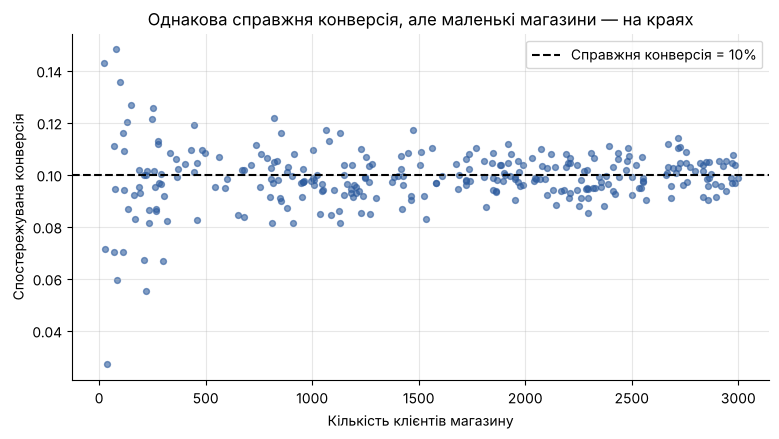

In [ ]:
# Чому «найкращі» і «найгірші» магазини часто — найменші
n_shops = 300
customers = rng.integers(20, 3_000, size=n_shops)            # скільки клієнтів у магазину
rate = rng.binomial(customers, 0.10) / customers             # справжня конверсія скрізь 10%!

plt.scatter(customers, rate, alpha=0.6, s=18, color='#2E5C9E')
plt.axhline(0.10, color='black', linestyle='--', label='Справжня конверсія = 10%')
plt.title('Однакова справжня конверсія, але маленькі магазини — на краях')
plt.xlabel('Кількість клієнтів магазину')
plt.ylabel('Спостережувана конверсія')
plt.legend()
plt.show()

Це «лійка»: у маленьких магазинів результати розкидані сильно, у великих — тісно біля 10%. Якщо відсортувати магазини за конверсією, на верхніх і нижніх місцях опиняться саме маленькі — **не тому, що вони кращі чи гірші, а тому, що в них мало даних**.

---
## 4. Центральна гранична теорема — інтуїтивно (⏱ 13 хв)

**Експеримент у думках:**
1. Маємо генеральну сукупність — наприклад, чеки всіх клієнтів. Розподіл **скошений** (а не дзвін).
2. Беремо випадкову вибірку з n клієнтів і рахуємо її середнє.
3. Повторюємо це тисячі разів. Отримуємо тисячі **вибіркових середніх**.
4. Будуємо гістограму цих середніх.

**Центральна гранична теорема (ЦГТ)** каже, що ця гістограма:

| | Що відбувається |
|---|---|
| **Центр** | збігається зі справжнім середнім μ |
| **Розкид** | дорівнює $\dfrac{\sigma}{\sqrt{n}}$ — це **стандартна похибка** (SE) |
| **Форма** | наближається до **нормальної** при великому n, **навіть якщо самі дані не нормальні** |

Орієнтир: для помірно скошених даних n ≥ 30 зазвичай достатньо. Для дуже скошених потрібно більше.

**Чому це важливо:** завдяки ЦГТ ми можемо будувати довірчі інтервали та проводити A/B-тести для середніх, використовуючи нормальний розподіл, хоча самі дані (гроші, час) майже ніколи не нормальні.

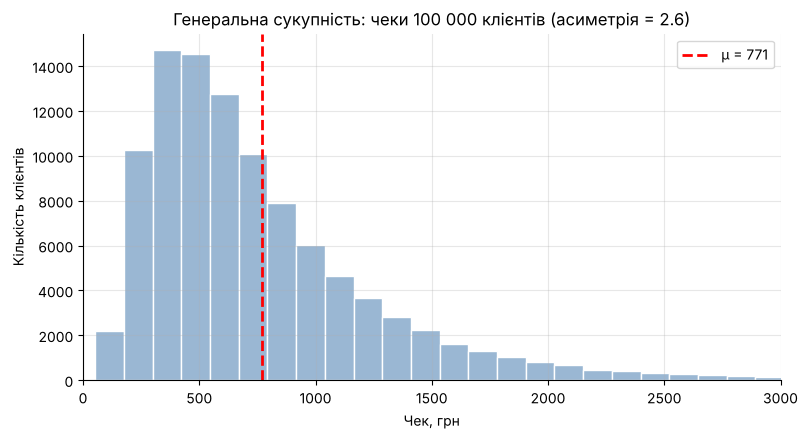

In [ ]:
checks = population['check']
sigma = checks.std()

plt.hist(checks, bins=80, color='#9ab7d3', edgecolor='white')
plt.axvline(mu, color='red', linestyle='--', linewidth=2, label=f'μ = {mu:.0f}')
plt.title(f'Генеральна сукупність: чеки 100 000 клієнтів (асиметрія = {checks.skew():.1f})')
plt.xlabel('Чек, грн')
plt.ylabel('Кількість клієнтів')
plt.xlim(0, 3000)
plt.legend()
plt.show()

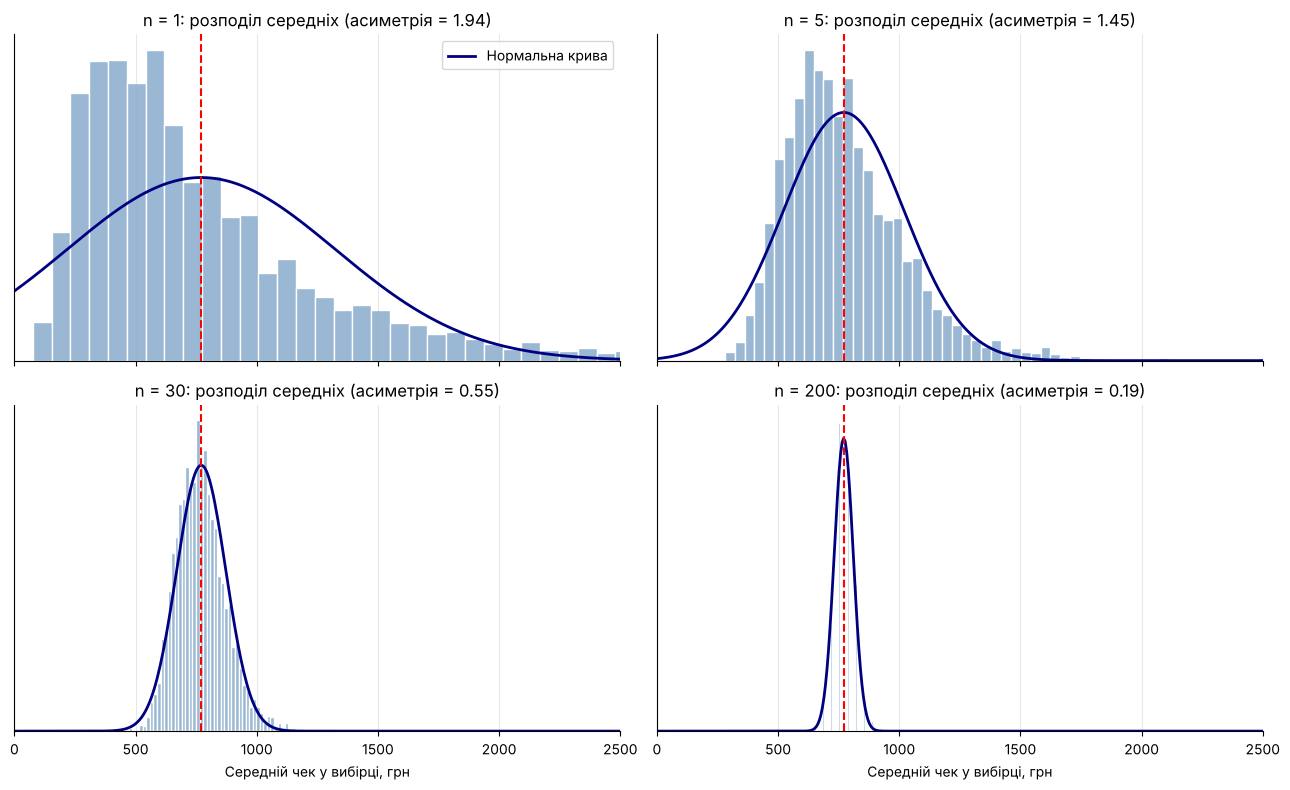

In [ ]:
def sample_means(data, n, k=3000):
    # Беремо k випадкових вибірок розміру n і повертаємо їхні середні
    values = data.to_numpy()
    idx = rng.integers(0, len(values), size=(k, n))
    return values[idx].mean(axis=1)

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for ax, n in zip(axes.flat, [1, 5, 30, 200]):
    m = sample_means(checks, n)
    ax.hist(m, bins=60, color='#9ab7d3', edgecolor='white', density=True)
    xs = np.linspace(0, 2500, 400)
    ax.plot(xs, stats.norm.pdf(xs, mu, sigma / np.sqrt(n)), color='navy', linewidth=2, label='Нормальна крива')
    ax.axvline(mu, color='red', linestyle='--')
    ax.set_title(f'n = {n}: розподіл середніх (асиметрія = {stats.skew(m):.2f})')
    ax.set_xlim(0, 2500)
    ax.set_yticks([])
axes[0, 0].legend()
for ax in axes[1]:
    ax.set_xlabel('Середній чек у вибірці, грн')
plt.tight_layout()
plt.show()

**Що видно:**
- **n = 1** — це просто вихідні дані, сильно скошені.
- **n = 5** — уже менш скошено.
- **n = 30** — майже дзвін.
- **n = 200** — дзвін, і дуже вузький: середні тісно біля μ.

Перевіримо формулу розкиду $SE = \sigma / \sqrt{n}$:

In [ ]:
rows = []
for n in [5, 30, 200, 1000]:
    m = sample_means(checks, n)
    rows.append({'n': n,
                 'Середнє з середніх': m.mean(),
                 'Розкид середніх (факт)': m.std(),
                 'σ / √n (формула)': sigma / np.sqrt(n)})
print(f'Справжнє μ = {mu:.1f},  σ = {sigma:.1f}')
pd.DataFrame(rows).set_index('n').round(1)

Справжнє μ = 771.0,  σ = 554.4


,Середнє з середніх,Розкид середніх (факт),σ / √n (формула)
n,,,
5,765.400,245.100,247.900
30,768.900,100.300,101.200
200,770.600,38.300,39.200
1000,770.700,17.800,17.500


> 💡 **Корінь із n — важливий урок для бізнесу.** Щоб зменшити похибку **вдвічі**, вибірку треба збільшити **вчетверо**. Щоб зменшити в 10 разів — у 100 разів. Тому точність коштує дорого, і в A/B-тестах так важливо заздалегідь рахувати потрібний розмір вибірки.

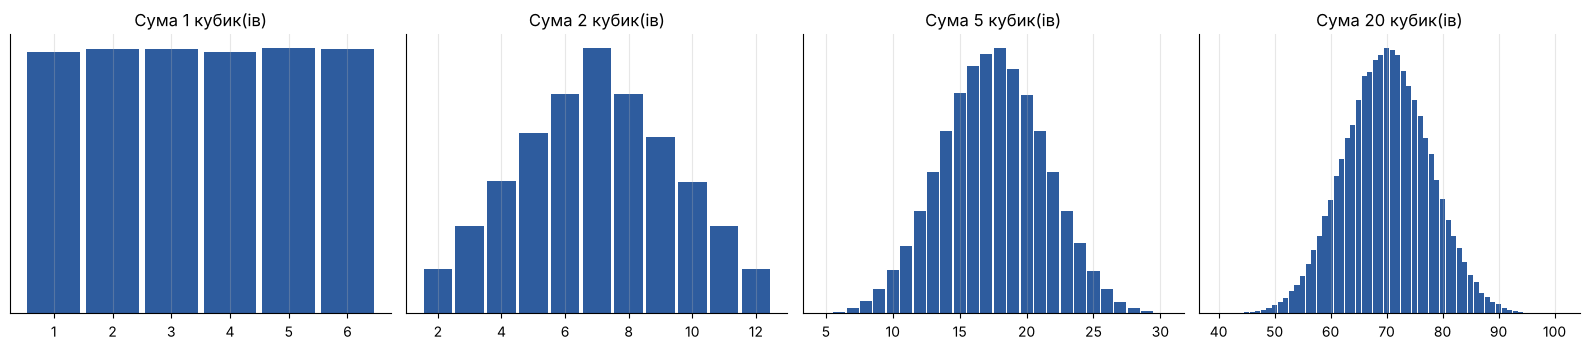

In [ ]:
# ЦГТ на кубиках: сума k кубиків стає «дзвоном»
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, k in zip(axes, [1, 2, 5, 20]):
    total = rng.integers(1, 7, size=(100_000, k)).sum(axis=1)
    vc = pd.Series(total).value_counts(normalize=True).sort_index()
    ax.bar(vc.index, vc.values, color='#2E5C9E', width=0.9)
    ax.set_title(f'Сума {k} кубик(ів)')
    ax.set_yticks([])
plt.tight_layout()
plt.show()

Один кубик — рівномірний розподіл (усі грані однаково ймовірні). Два — «трикутник». П'ять і більше — дзвін. Рівномірний розподіл зовсім не схожий на нормальний, але **сума (або середнє)** багатьох незалежних значень стає нормальною. У цьому вся суть ЦГТ.

---
# Частина 2. Кореляція та зв'язки між змінними

Тепер нас цікавлять **дві змінні одночасно**: чи пов'язані вони? Якщо одна росте, що робить інша?

Візьмемо дані інтернет-магазину за 2 роки (104 тижні).

| Колонка | Що означає |
|---|---|
| `ad_spend` | витрати на рекламу за тиждень, тис. грн |
| `sales` | кількість продажів за тиждень |
| `discount_pct` | середня знижка, % |
| `avg_check` | середній чек, грн |
| `temperature` | середня температура тижня, °C |
| `complaints` | кількість скарг |

In [ ]:
weeks = 104
ad = rng.uniform(10, 100, weeks)
disc = rng.uniform(0, 30, weeks)
temp = 10 + 12 * np.sin(np.linspace(0, 4 * np.pi, weeks)) + rng.normal(0, 3, weeks)

shop = pd.DataFrame({
    'ad_spend':     ad.round(1),
    'sales':        np.round(300 + 6 * ad + 4 * disc + rng.normal(0, 70, weeks)).astype(int),
    'discount_pct': disc.round(1),
    'avg_check':    np.round(650 - 7 * disc + rng.normal(0, 40, weeks)).astype(int),
    'temperature':  temp.round(1),
    'complaints':   rng.poisson(6, weeks),
})
shop.head()

,ad_spend,sales,discount_pct,avg_check,temperature,complaints
0,57.600,742,15.400,611,14.400,4
1,91.800,903,13.700,469,7.800,7
2,54.100,623,6.400,653,7.200,6
3,16.800,316,4.800,640,10.800,4
4,46.200,647,4.000,636,10.800,6


---
## 5. Діаграма розсіювання (⏱ 7 хв)

**Діаграма розсіювання** (*scatter plot*): кожна точка — один об'єкт (у нас тиждень). По осі X — одна змінна, по осі Y — інша.

**На що дивитися:**
1. **Напрям:** точки йдуть угору (позитивний зв'язок), вниз (негативний) чи хаотично (немає зв'язку)?
2. **Форма:** це приблизно пряма лінія чи крива?
3. **Сила:** точки тісно лежать уздовж лінії чи це «хмара»?
4. **Викиди:** чи є точки далеко від решти?
5. **Групи:** чи розбиваються точки на окремі «острівці»?

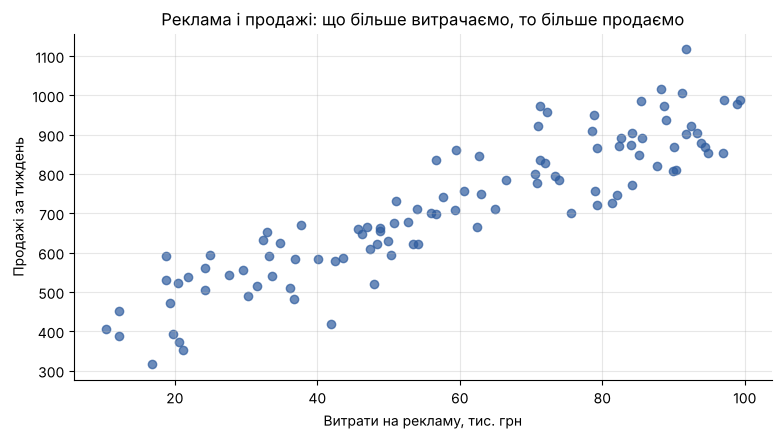

In [ ]:
plt.scatter(shop['ad_spend'], shop['sales'], color='#2E5C9E', alpha=0.7)
plt.title('Реклама і продажі: що більше витрачаємо, то більше продаємо')
plt.xlabel('Витрати на рекламу, тис. грн')
plt.ylabel('Продажі за тиждень')
plt.show()

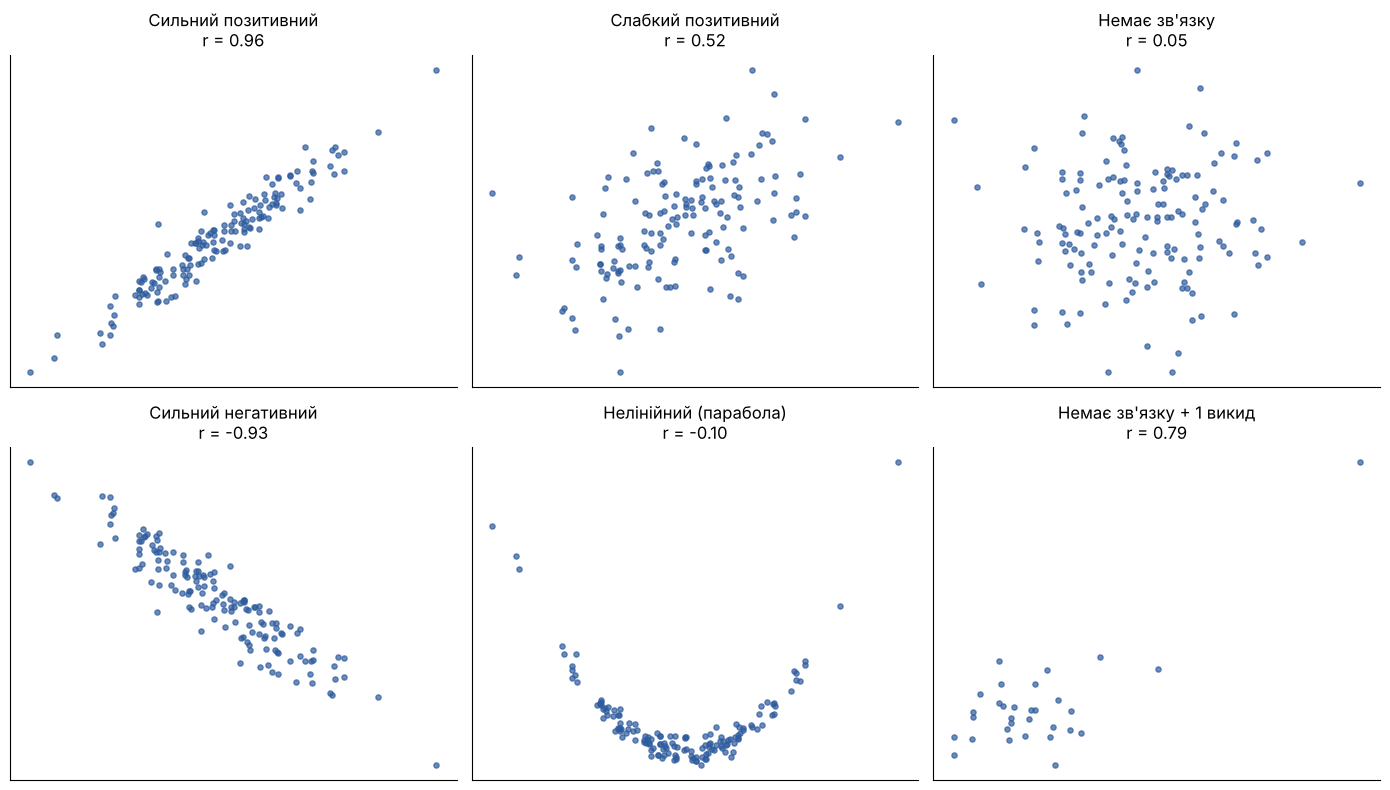

In [ ]:
# Галерея типових картинок
n_pts = 150
x = rng.normal(0, 1, n_pts)
gallery = [
    ('Сильний позитивний',   x, x + rng.normal(0, 0.3, n_pts)),
    ('Слабкий позитивний',   x, x + rng.normal(0, 1.8, n_pts)),
    ('Немає зв\'язку',        x, rng.normal(0, 1, n_pts)),
    ('Сильний негативний',   x, -x + rng.normal(0, 0.35, n_pts)),
    ('Нелінійний (парабола)', x, x ** 2 + rng.normal(0, 0.3, n_pts)),
    ('Немає зв\'язку + 1 викид', np.append(x[:30], 8), np.append(rng.normal(0, 1, 30), 8)),
]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (title, xs, ys) in zip(axes.flat, gallery):
    r = np.corrcoef(xs, ys)[0, 1]
    ax.scatter(xs, ys, s=14, alpha=0.7, color='#2E5C9E')
    ax.set_title(f'{title}\nr = {r:.2f}')
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

Над кожним графіком є число **r** — коефіцієнт кореляції. Що це таке, розберемося за кілька хвилин. Але вже зараз зверніть увагу на два останні графіки:
- у **параболі** зв'язок дуже сильний, а r ≈ 0;
- у графіку з **одним викидом** зв'язку немає, а r високий.

Тобто **одне число не замінює погляду на графік**.

---
## 6. Коваріація (⏱ 8 хв)

**Коваріація** показує, чи змінюються дві змінні **разом**:

$$\text{cov}(x, y) = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{n - 1}$$

**Інтуїція через знаки.** Для кожної точки дивимось, чи вона вище чи нижче середнього по X і по Y:

| x вище середнього? | y вище середнього? | Добуток $(x-\bar{x})(y-\bar{y})$ |
|---|---|---|
| так | так | **+** |
| ні | ні | **+** (мінус на мінус) |
| так | ні | **−** |
| ні | так | **−** |

Якщо більшість точок дають «+», коваріація додатна: змінні ростуть разом. Якщо більшість дає «−» — від'ємна: одна росте, інша падає. Якщо «+» і «−» приблизно порівну — коваріація близька до 0.

> ⚠️ **Проблема коваріації:** її **знак** зрозумілий, а **величина** — ні. Вона залежить від одиниць виміру. Порахуйте рекламу в гривнях замість тисяч гривень — і коваріація зросте в 1000 разів, хоча зв'язок не змінився.

In [ ]:
# Маленький приклад: 6 тижнів
x = np.array([20, 35, 50, 60, 75, 90])           # реклама, тис. грн
y = np.array([420, 480, 650, 640, 780, 870])     # продажі

dx, dy = x - x.mean(), y - y.mean()
table = pd.DataFrame({'x': x, 'y': y, 'x − x̄': dx, 'y − ȳ': dy, 'добуток': dx * dy})
print(f'x̄ = {x.mean():.1f},  ȳ = {y.mean():.1f}')
table

x̄ = 55.0,  ȳ = 640.0


,x,y,x − x̄,y − ȳ,добуток
0,20,420,-35.000,-220.000,7700.000
1,35,480,-20.000,-160.000,3200.000
2,50,650,-5.000,10.000,-50.000
3,60,640,5.000,0.000,0.000
4,75,780,20.000,140.000,2800.000
5,90,870,35.000,230.000,8050.000


In [ ]:
cov_manual = (dx * dy).sum() / (len(x) - 1)
print(f'Коваріація вручну:  {cov_manual:.1f}')
print(f'np.cov(x, y)[0, 1]: {np.cov(x, y)[0, 1]:.1f}')        # np.cov повертає матрицю 2×2
print(f'pandas .cov():      {pd.Series(x).cov(pd.Series(y)):.1f}')

Коваріація вручну:  4340.0
np.cov(x, y)[0, 1]: 4340.0
pandas .cov():      4340.0


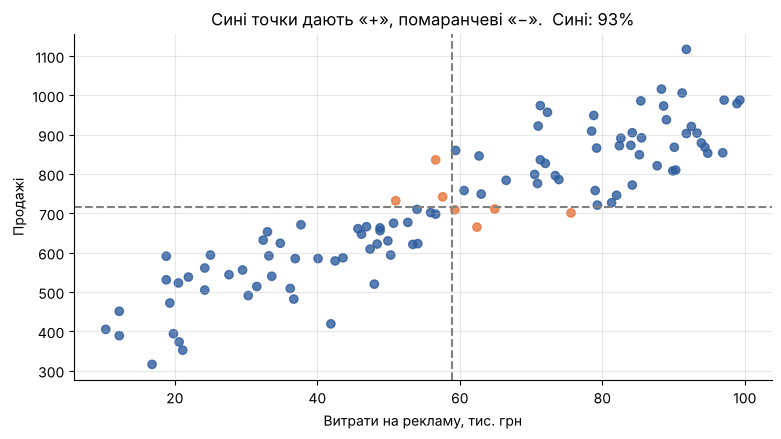

In [ ]:
# Квадранти: розфарбуємо точки за знаком добутку
dx = shop['ad_spend'] - shop['ad_spend'].mean()
dy = shop['sales'] - shop['sales'].mean()
colors = np.where(dx * dy > 0, '#2E5C9E', '#E8743B')

plt.scatter(shop['ad_spend'], shop['sales'], c=colors, alpha=0.8)
plt.axvline(shop['ad_spend'].mean(), color='gray', linestyle='--')
plt.axhline(shop['sales'].mean(), color='gray', linestyle='--')
plt.title(f'Сині точки дають «+», помаранчеві «−».  Сині: {(dx * dy > 0).mean():.0%}')
plt.xlabel('Витрати на рекламу, тис. грн')
plt.ylabel('Продажі')
plt.show()

In [ ]:
# Проблема одиниць виміру
cov_thousands = shop['ad_spend'].cov(shop['sales'])
cov_uah = (shop['ad_spend'] * 1000).cov(shop['sales'])
r_thousands = shop['ad_spend'].corr(shop['sales'])
r_uah = (shop['ad_spend'] * 1000).corr(shop['sales'])

print(f'Реклама в тис. грн: коваріація = {cov_thousands:>12,.0f}   кореляція = {r_thousands:.3f}')
print(f'Реклама в грн:      коваріація = {cov_uah:>12,.0f}   кореляція = {r_uah:.3f}')

Реклама в тис. грн: коваріація =        4,069   кореляція = 0.904
Реклама в грн:      коваріація =    4,069,411   кореляція = 0.904


Коваріація зросла в 1000 разів, а **кореляція не змінилась**. Саме тому на практиці майже завжди дивляться на кореляцію.

---
## 7. Коефіцієнт кореляції Пірсона (⏱ 12 хв)

**Кореляція Пірсона** — це коваріація, «очищена» від одиниць виміру:

$$r = \frac{\text{cov}(x, y)}{s_x \cdot s_y}$$

**Властивості:**
- r завжди від **−1 до +1**.
- **Знак** — напрям: «+» ростуть разом, «−» одна росте, інша падає.
- **Модуль** — сила **лінійного** зв'язку: 1 — точки ідеально на прямій, 0 — лінійного зв'язку немає.
- Не залежить від одиниць виміру.

**Орієнтовна шкала** (умовна, у різних галузях різні звички):

| \|r\| | Сила зв'язку |
|---|---|
| < 0.1 | практично немає |
| 0.1 – 0.3 | слабкий |
| 0.3 – 0.5 | помірний |
| 0.5 – 0.7 | помітний |
| > 0.7 | сильний |

**Бонус:** r² — частка розкиду y, яку «пояснює» лінійний зв'язок з x. При r = 0.7 це лише 49%.

In [ ]:
# Три способи порахувати r
x, y = shop['ad_spend'], shop['sales']

r_manual = x.cov(y) / (x.std() * y.std())
r_numpy = np.corrcoef(x, y)[0, 1]
r_pandas = x.corr(y)

print(f'Вручну:          {r_manual:.3f}')
print(f'np.corrcoef:     {r_numpy:.3f}')
print(f'pandas .corr():  {r_pandas:.3f}')
print(f'r² = {r_pandas ** 2:.2f} → реклама «пояснює» ≈ {r_pandas ** 2:.0%} коливань продажів')

Вручну:          0.904
np.corrcoef:     0.904
pandas .corr():  0.904
r² = 0.82 → реклама «пояснює» ≈ 82% коливань продажів


In [ ]:
# Кореляційна матриця: усі пари колонок одразу
corr = shop.corr()
corr.round(2)

,ad_spend,sales,discount_pct,avg_check,temperature,complaints
ad_spend,1.000,0.900,0.110,-0.200,-0.010,0.090
sales,0.900,1.000,0.270,-0.340,0.050,0.020
discount_pct,0.110,0.270,1.000,-0.860,0.070,-0.090
avg_check,-0.200,-0.340,-0.860,1.000,-0.010,0.070
temperature,-0.010,0.050,0.070,-0.010,1.000,-0.100
complaints,0.090,0.020,-0.090,0.070,-0.100,1.000


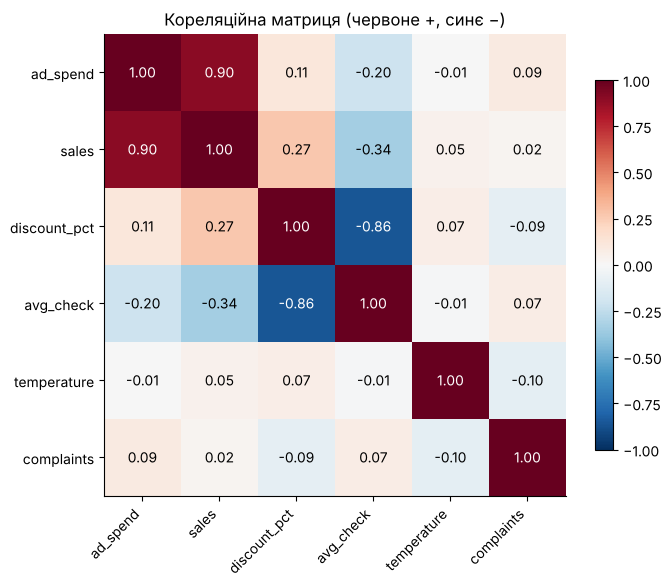

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center',
                color='white' if abs(corr.iloc[i, j]) > 0.6 else 'black')
ax.grid(False)
plt.colorbar(im, ax=ax, shrink=0.8)
plt.title('Кореляційна матриця (червоне +, синє −)')
plt.show()

**Читаємо матрицю:**
- Діагональ завжди 1: змінна ідеально корелює сама з собою.
- Матриця симетрична: corr(A, B) = corr(B, A).
- `ad_spend` ↔ `sales` — сильний позитивний зв'язок.
- `discount_pct` ↔ `avg_check` — сильний негативний: більша знижка → менший чек.
- `discount_pct` ↔ `sales` — слабкий позитивний: знижки трохи збільшують кількість продажів.
- `complaints` майже ні з чим не корелює.

### ⚠️ Три пастки кореляції Пірсона

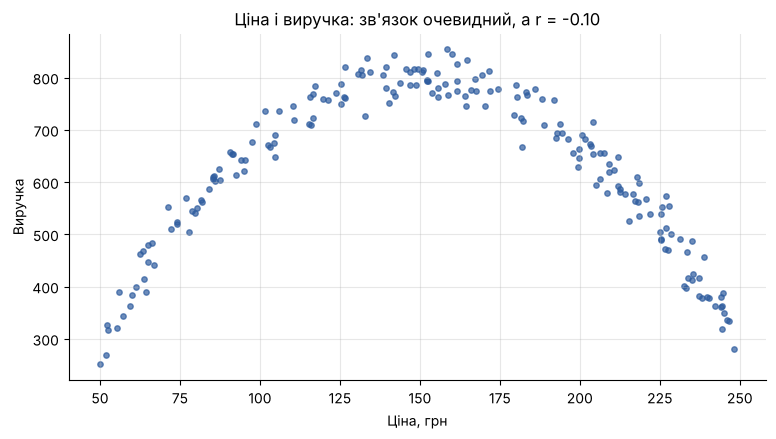

In [ ]:
# Пастка 1: Пірсон бачить тільки ЛІНІЙНІ зв'язки
price = rng.uniform(50, 250, 200)
revenue = -0.05 * (price - 150) ** 2 + 800 + rng.normal(0, 30, 200)   # «перевернута U»

plt.scatter(price, revenue, s=15, alpha=0.7, color='#2E5C9E')
plt.title(f'Ціна і виручка: зв\'язок очевидний, а r = {np.corrcoef(price, revenue)[0, 1]:.2f}')
plt.xlabel('Ціна, грн')
plt.ylabel('Виручка')
plt.show()

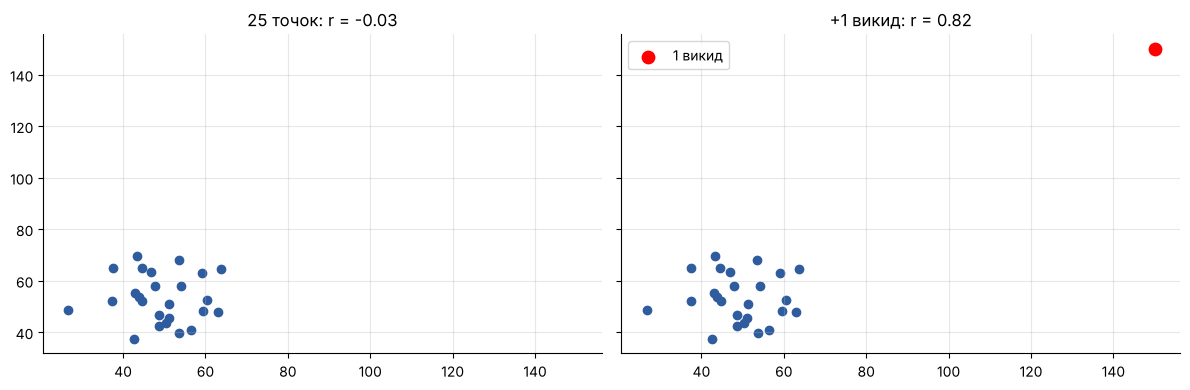

Кореляція Спірмена (за рангами) стійкіша до викидів:
  Пірсон: 0.82   Спірмен: 0.01


In [ ]:
# Пастка 2: один викид може «створити» кореляцію
rng_o = np.random.default_rng(0)      # окремий генератор для цього прикладу
a = rng_o.normal(50, 10, 25)
b = rng_o.normal(50, 10, 25)
a_out = np.append(a, 150)
b_out = np.append(b, 150)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
axes[0].scatter(a, b, color='#2E5C9E')
axes[0].set_title(f'25 точок: r = {np.corrcoef(a, b)[0, 1]:.2f}')
axes[1].scatter(a_out, b_out, color='#2E5C9E')
axes[1].scatter([150], [150], color='red', s=80, label='1 викид')
axes[1].set_title(f'+1 викид: r = {np.corrcoef(a_out, b_out)[0, 1]:.2f}')
axes[1].legend()
plt.tight_layout()
plt.show()

print('Кореляція Спірмена (за рангами) стійкіша до викидів:')
print(f"  Пірсон: {pd.Series(a_out).corr(pd.Series(b_out)):.2f}   "
      f"Спірмен: {pd.Series(a_out).corr(pd.Series(b_out), method='spearman'):.2f}")

**Пастка 3: квартет Енскомба.** Статистик Френсіс Енскомб у 1973 році придумав 4 набори даних з **однаковими** середніми, дисперсіями і кореляцією (r ≈ 0.82). Подивіться, наскільки різні вони насправді.

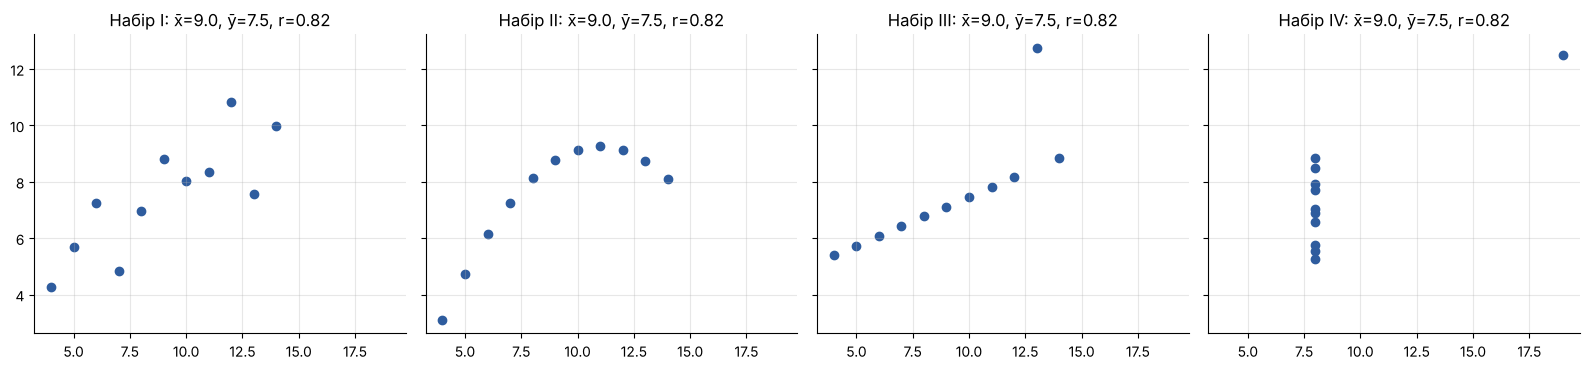

In [ ]:
anscombe_x = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
anscombe = {
    'I':   (anscombe_x, [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
    'II':  (anscombe_x, [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
    'III': (anscombe_x, [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
    'IV':  ([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8], [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]),
}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharex=True, sharey=True)
for ax, (name, (xs, ys)) in zip(axes, anscombe.items()):
    ax.scatter(xs, ys, color='#2E5C9E')
    ax.set_title(f'Набір {name}: x̄={np.mean(xs):.1f}, ȳ={np.mean(ys):.1f}, r={np.corrcoef(xs, ys)[0, 1]:.2f}')
plt.tight_layout()
plt.show()

1. Нормальний лінійний зв'язок із шумом.
2. Ідеальна **крива**, не пряма.
3. Ідеальна пряма + **один викид**.
4. Зв'язку немає зовсім, кореляцію «створила» **одна точка**.

> 💡 **Правило:** **спершу графік, потім кореляція.** Одне число може приховати все найцікавіше.

---
## 8. Кореляція ≠ причинність (⏱ 10 хв)

Якщо A і B корелюють, можливі **кілька** пояснень:

| Пояснення | Схема | Приклад |
|---|---|---|
| **A спричиняє B** | A → B | реклама → продажі (найімовірніше) |
| **Зворотна причинність** | B → A | «у районах із більшою кількістю поліцейських більше злочинів» — насправді поліцію відправляють туди, де злочинів більше |
| **Третя змінна** (*конфаундер*) | A ← C → B | продажі морозива і кількість утоплень корелюють, бо обидва ростуть у **спеку** |
| **Випадковість** | — | кількість фільмів з Ніколасом Кейджем і кількість утоплень у басейнах (сайт *Spurious Correlations* Тайлера Вігена) |

**Як довести причинність?** Найнадійніше — **експеримент** (A/B-тест): випадково ділимо людей на групи, змінюємо лише одне, порівнюємо. Випадковий розподіл «зрівнює» всі треті змінні між групами.

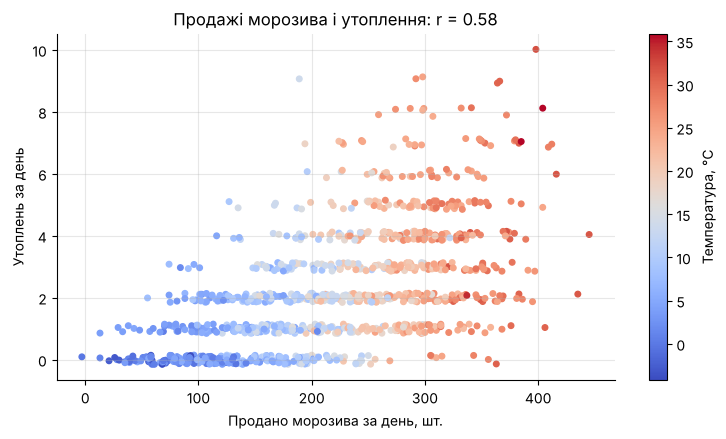

In [ ]:
# Морозиво і утоплення: 3 роки щоденних даних, справжня причина обох — температура
days = 3 * 365
t = 15 + 12 * np.sin(np.linspace(-np.pi / 2, 5.5 * np.pi, days)) + rng.normal(0, 3, days)
summer = pd.DataFrame({
    'temperature': t.round(1),
    'ice_cream':   np.round(80 + 9 * t + rng.normal(0, 35, days)),
    'drownings':   rng.poisson(np.clip(0.15 * t, 0.05, None)),
})
r_ic = summer['ice_cream'].corr(summer['drownings'])

sc = plt.scatter(summer['ice_cream'], summer['drownings'] + rng.uniform(-0.15, 0.15, days),
                 c=summer['temperature'], cmap='coolwarm', s=16)
plt.colorbar(sc, label='Температура, °C')
plt.title(f'Продажі морозива і утоплення: r = {r_ic:.2f}')
plt.xlabel('Продано морозива за день, шт.')
plt.ylabel('Утоплень за день')
plt.show()

Кольори все пояснюють: праворуч угорі **червоні** точки — спекотні дні, ліворуч унизу **сині** — холодні. Морозиво не топить людей. У спеку люди і морозиво купують, і купаються.

**Перевірка:** якщо температура — справжня причина, то **серед днів з однаковою температурою** зв'язок морозива з утопленнями має зникнути.

In [ ]:
summer['temp_group'] = pd.cut(summer['temperature'], bins=[-10, 5, 10, 15, 20, 25, 40])

within = summer.groupby('temp_group', observed=True).apply(
    lambda g: pd.Series({'днів': len(g), 'кореляція': g['ice_cream'].corr(g['drownings'])}))

print(f'Кореляція за всі 3 роки: {r_ic:.2f}')
print('\nКореляція всередині груп зі схожою температурою:')
print(within.round(2))

Кореляція за всі 3 роки: 0.58

Кореляція всередині груп зі схожою температурою:
              днів  кореляція
temp_group                   
(-10, 5]   188.000      0.110
(5, 10]    209.000      0.160
(10, 15]   170.000      0.160
(15, 20]   130.000      0.080
(20, 25]   218.000      0.110
(25, 40]   180.000      0.020


Усередині температурних груп кореляція різко падає — до нуля або слабких значень. Невеликий залишок пояснюється тим, що навіть у групі «15–20 °C» температура трохи різниться від дня до дня. Зв'язок «морозиво → утоплення» майже повністю пояснюється температурою.

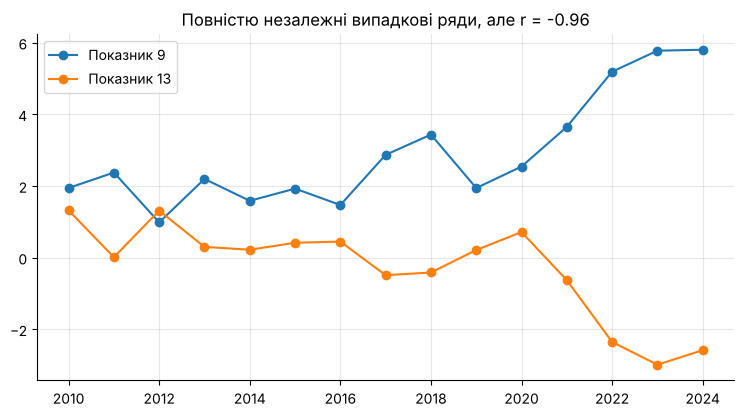

Перевірено пар: 780


In [ ]:
# Випадкові збіги: 40 незалежних випадкових рядів по 15 «років»
n_series, n_years = 40, 15
series = pd.DataFrame(rng.normal(0, 1, (n_years, n_series)).cumsum(axis=0),
                      columns=[f'Показник {i}' for i in range(n_series)])

c = series.corr().abs()
c = c.where(~np.eye(len(c), dtype=bool), 0)    # прибираємо діагональ (кореляцію ряду з самим собою)
a_name, b_name = c.stack().idxmax()

plt.plot(range(2010, 2010 + n_years), series[a_name], marker='o', label=a_name)
plt.plot(range(2010, 2010 + n_years), series[b_name], marker='o', label=b_name)
plt.title(f'Повністю незалежні випадкові ряди, але r = {series[a_name].corr(series[b_name]):.2f}')
plt.legend()
plt.show()
print(f'Перевірено пар: {n_series * (n_series - 1) // 2}')

Ми згенерували 40 **повністю незалежних** випадкових рядів. Серед 780 пар обов'язково знайдеться пара з дуже високою кореляцією — просто тому, що ми шукали серед багатьох. Що більше змінних перебираєте, то більше «відкриттів», які є лише збігами.

---
## 9. 🧾 Підсумок (⏱ 5 хв)

| Поняття | Головна думка |
|---|---|
| **Ймовірність** | число від 0 до 1; рахуємо класично (сприятливі / всі) або за частотою |
| **«Хоча б один»** | 1 − P(жодного) |
| **Генеральна сукупність vs вибірка** | параметр (μ) невідомий, статистику (x̄) рахуємо з вибірки |
| **Зміщена вибірка** | великий розмір не рятує від поганого відбору |
| **Закон великих чисел** | середнє з багатьох спроб → справжнє значення; на малих вибірках — великий «шум» |
| **ЦГТ** | середні вибірок розподілені нормально з розкидом σ/√n, навіть якщо дані скошені |
| **Діаграма розсіювання** | завжди починаємо з неї |
| **Коваріація** | знак показує напрям, але величина залежить від одиниць |
| **Кореляція Пірсона** | від −1 до 1, лише для лінійних зв'язків, чутлива до викидів |
| **Кореляція ≠ причинність** | третя змінна, зворотна причинність, випадковість; причинність доводять експериментом |

### 5 речей, які варто запам'ятати

1. **Якість вибірки важливіша за розмір.** Мільйон відповідей зі зміщеної вибірки гірші за тисячу з випадкової.
2. **Маленькі вибірки «стрибають».** Не робіть висновків про конверсію з 30 відвідувачів.
3. **Похибка падає як 1/√n.** Удвічі точніше = вчетверо більше даних.
4. **Спершу графік, потім r.** Квартет Енскомба нагадує, що одне число може обманути.
5. **Корелює ≠ спричиняє.** Завжди питайте: «А що, якщо є третя змінна?»

---
## ✍️ Перевірте себе (домашнє завдання)

Під кожним завданням — порожня клітинка для коду.

**Завдання 1.** У компанії 3 сервери. Кожен незалежно від інших падає протягом дня з ймовірністю 0.02. Яка ймовірність, що за день впаде **хоча б один**? Порахуйте за формулою і перевірте симуляцією.

In [ ]:
# Ваш код тут

**Завдання 2.** Візьміть з `population['check']` випадкову вибірку з 400 клієнтів (`random_state=42`). Порахуйте її середнє і стандартну похибку `s / √n`. На скільки стандартних похибок вибіркове середнє відрізняється від справжнього `mu`?

In [ ]:
# Ваш код тут

**Завдання 3.** Для датафрейму `shop` знайдіть пару **різних** колонок з найсильнішою **від'ємною** кореляцією. Побудуйте для неї діаграму розсіювання.

In [ ]:
# Ваш код тут

**Завдання 4.** Для кожного твердження визначте найімовірніше пояснення кореляції (причинність, зворотна причинність, третя змінна, випадковість):

   а) Діти з більшим розміром взуття краще читають.
   б) Люди, які п'ють багато кави, частіше хворіють на рак легенів (подумайте про паління).
   в) У містах з більшою кількістю лікарень вища смертність.
   г) Що більше годин студент витрачає на навчання, то вищий бал.

*Ваша відповідь:* _(двічі клацніть, щоб написати)_

---
## 🔑 Розв'язки (для викладача)

In [ ]:
# Завдання 1
p_fail = 0.02
p_formula = 1 - (1 - p_fail) ** 3
p_sim = (rng.random((200_000, 3)) < p_fail).any(axis=1).mean()
print(f'Формула: {p_formula:.4f} | Симуляція: {p_sim:.4f}')

Формула: 0.0588 | Симуляція: 0.0577


In [ ]:
# Завдання 2
s400 = population['check'].sample(400, random_state=42)
se = s400.std() / np.sqrt(len(s400))
print(f'x̄ = {s400.mean():.1f}, SE = {se:.1f}, μ = {mu:.1f}')
print(f'Відхилення: {(s400.mean() - mu) / se:+.2f} SE')

x̄ = 752.4, SE = 29.0, μ = 771.0
Відхилення: -0.64 SE


Найсильніша від'ємна кореляція: ('discount_pct', 'avg_check') -0.86


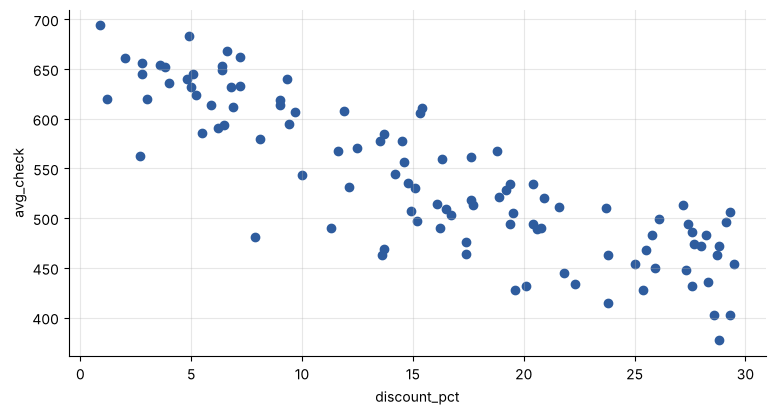

In [ ]:
# Завдання 3
c = shop.corr()
c = c.where(~np.eye(len(c), dtype=bool))   # прибираємо діагональ
pair = c.stack().idxmin()
print('Найсильніша від\'ємна кореляція:', pair, round(c.stack().min(), 2))
plt.scatter(shop[pair[0]], shop[pair[1]], color='#2E5C9E')
plt.xlabel(pair[0]); plt.ylabel(pair[1])
plt.show()

**Завдання 4.**
- а) **Третя змінна:** вік. Старші діти мають більший розмір взуття і краще читають.
- б) **Третя змінна:** паління. Курці частіше п'ють багато кави, а рак спричиняє паління.
- в) **Зворотна причинність / третя змінна:** у великі лікарні везуть найважчих пацієнтів; а великі міста мають і більше лікарень, і більше населення.
- г) **Найімовірніше причинність** (навчання → бал), але можлива й третя змінна: мотивація впливає і на години, і на бал.